remove the drop first when using the ensembles, both in the one hot and the handle missing functions

In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ucphm import *
from functions.new_variables import *
from functions.ensembles import *
from scipy.stats import skew, shapiro

In [2]:
dataset = pd.read_excel('../../BreastCareCond.xlsx')
data_code = pd.read_excel('../../Codificação variaveis.xlsx')

In [3]:
#Defining the proposed has good treatment variables to use (the empty ones were removed)
relevant_variables = ['PERSON_ID', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'EBC', 'Survival days']
numerical_variables = ['Age', 'Ki67 positive cells (%) at CB']
categorical_variables = ['Grade at CB', 'Side location of the lesion', 'Classification with respect to other lesions', 
                         'Type of invasion at CB', 'Isotype at CB', 
                         'Oestrogen receptor status at CB', 'Progesterone receptor status at CB', 
                         'Disease extent', 'Her2 overexpression (with immunohystochemistry) at CB', 
                         'N (Regional nodes affected)']
                         
date_columns = ['Date of CB ', 'Date of 1st breast operation', 'Date of intervention on sentinel lymph node',
                'Date of intervention (axilla)']

In [4]:
#correcting th error in the column name
dataset.rename(columns={'Istotype at CB': 'Isotype at CB'}, inplace=True)

In [5]:
dataset = date_of_diagnosis(dataset, date_columns)

relevant_dates = ['Date of diagnosis', 'Date of 1st regional recurrence']
dataset = remove_zeros_na(dataset, relevant_dates)
dataset = format_date(dataset, relevant_dates)

dataset = survival_days(dataset, ['Date of diagnosis'], ['Date of 1st regional recurrence'])
dataset = tte_negative_patients(dataset)
dataset = filter_EBC(dataset)
dataset.reset_index(drop=True, inplace=True)

In [6]:
# pT(dataset)
# cT (dataset)
# clinical_staging(dataset)
# didn't place the ct in the new variables, the pt is already at the top
# new_variables = ['Cancer stage']
# categorical_variables = categorical_variables + new_variables

In [7]:
change_to_numeric(dataset, numerical_variables)
change_to_categorical(dataset, categorical_variables)

Done
Done


In [8]:
columns_to_map = {
    'Side location of the lesion': {'L': 0, 'R': 1},
    'Type of invasion at CB': {1: 0, 2: 1},
    'Oestrogen receptor status at CB': {1: 0, 2: 1},
    'Progesterone receptor status at CB': {1: 0, 2: 1},
    'N (Regional nodes affected)': {0: 0, 1: 1, 2: 2_3, 3: 2_3}
    }

for column, mapping in columns_to_map.items():
    dataset[column] = dataset[column].map(mapping)

In [9]:
# Replace missing values with 0 (not the mode)
# dataset['Isotype at CB'] = dataset['Isotype at CB'].fillna(0)

#fit with the mode
mode_variables = ['Isotype at CB', 'Grade at CB', 'Side location of the lesion', 'Classification with respect to other lesions', 'N (Regional nodes affected)', 'Type of invasion at CB', 'Disease extent']
fill_with_mode(dataset, mode_variables)

'Done'

Also drop none here

In [10]:
handle_missing = ['Oestrogen receptor status at CB', 'Her2 overexpression (with immunohystochemistry) at CB', 'Progesterone receptor status at CB']
dataset, new_columns = one_hot_encode_with_missing_indicator(dataset, handle_missing)
categorical_variables = [col for col in categorical_variables if col not in handle_missing]
categorical_variables.extend(new_columns)

In [11]:
median = ['Ki67 positive cells (%) at CB']
median_imputer(dataset, numerical_variables)

'Done'

In [12]:
one_hot_variables = ['Grade at CB', 'N (Regional nodes affected)', 'Classification with respect to other lesions', 'Disease extent', 'Isotype at CB']
ohe_dataset, new_column_names = one_hot_encoding(dataset, one_hot_variables, drop_first=None)

In [13]:
categorical_variables = [col for col in categorical_variables if col not in one_hot_variables]
categorical_variables.extend(new_column_names.tolist())

selected_variables = relevant_variables + numerical_variables + categorical_variables

In [14]:
ohe_dataset['Cause of death'][ohe_dataset['Cause of death'] == 2]

1380    2.0
Name: Cause of death, dtype: float64

In [15]:
# Filter patients with Cause of death == 1 and Regional LN recurrence == 1
source_df = dataset if 'Cause of death' in dataset.columns else ohe_dataset

patients_both_1 = source_df[
    (source_df['Cause of death'] == 1) &
    (source_df['Regional LN recurrence'] == 1)
]

print(f"Number of patients: {len(patients_both_1)}")
patients_both_1[['PERSON_ID', 'Cause of death', 'Regional LN recurrence', 'Survival days']].head(20)

Number of patients: 9


,PERSON_ID,Cause of death,Regional LN recurrence,Survival days
1136,1175,1.0,1.0,345.0
1283,1320,1.0,1.0,799.0
1316,1349,1.0,1.0,986.0
1413,1449,1.0,1.0,192.0
1488,1524,1.0,1.0,994.0
1765,1789,1.0,1.0,381.0
1961,1980,1.0,1.0,599.0
2053,2070,1.0,1.0,395.0
2610,2625,1.0,1.0,622.0


In [16]:
treatment_variables = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 
                       'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                         'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
                        'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs', 'Endocrine therapy performed']
selected_variables_treat = selected_variables + treatment_variables

survival_dataset = ohe_dataset[selected_variables_treat].copy()

Now the treatment variables, just because it was already made

In [17]:
dataset = survival_dataset

In [18]:
numerical_data, categorical_data = type_separation(data_code, treatment_variables)
len(numerical_data), len(categorical_data)

(3, 10)

In [19]:
replace_missing_values(dataset, numerical_data, 0)

Done


In [20]:
dataset.drop(index=0, inplace=True)
dataset.reset_index(inplace=True, drop=True)
replace_missing_values(dataset, categorical_data, 0)

Done


In [21]:
variable_two_to_zero = ['Adjuvant chemotherapy', 'Chemotherapy performed', 'Endocrine therapy performed']
two_to_zero(dataset, variable_two_to_zero)

bio_variable = 'Adjuvant therapy with biological drugs'
dataset = encode_bio_therapy(dataset, bio_variable)

In [22]:
feature_columns = ['Adjuvant therapy using biological drugs', 'Trastuzumab or other drugs']
feature_columns = feature_columns + categorical_data + numerical_data

treatment_variables = [col for col in feature_columns if col not in bio_variable]

In [23]:
to_remove = ['PERSON_ID', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'EBC', 'Survival days']
important_variables = ['PERSON_ID', 'Regional LN recurrence', 'Survival days']
diagnosis_variables = [col for col in selected_variables if col not in to_remove]
selected_columns = important_variables + treatment_variables + diagnosis_variables

In [24]:
survival_dataset = dataset[selected_columns]

In [25]:
# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False) & (survival_dataset['Regional LN recurrence'] == 1))

# For each duplicated PERSON_ID with recurrence, keep only the first row
to_remove = (
    survival_dataset[mask]
    .groupby('PERSON_ID')
    .tail(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [26]:
# Check if there are any NaN values in the dataset
contains_nan = survival_dataset.isnull().any().any()
print("Does survival_dataset contain NaN values?", contains_nan)

# Optionally, to see which columns contain NaN values
nan_columns = survival_dataset.columns[survival_dataset.isnull().any()].tolist()
print("Columns with NaN values:", nan_columns)

Does survival_dataset contain NaN values? False
Columns with NaN values: []


In [27]:
survival_dataset.to_csv("data.csv")

In [28]:
with open("diagnosis.txt", "w") as file:
    for item in diagnosis_variables:
        file.write(str(item) + "\n")
with open("treatment.txt", "w") as file:
    for item in treatment_variables:
        file.write(str(item) + "\n")

# Distribution Fitting Analysis

Test which parametric distribution best fits the survival data: Weibull, Log-normal, Log-logistic, Exponential, etc.

In [ ]:
# Import required libraries for distribution fitting
from scipy import stats
from scipy.stats import weibull_min, lognorm, exponweib, gamma, expon
from sksurv.nonparametric import kaplan_meier_estimator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [30]:
# Prepare survival data (adjust variable names as needed)
# Replace with your actual variable names for event and time


data_x = survival_dataset[selected_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

event_times = data_y['time']  # Observed times
event_occurred = data_y['event']  # 1 if event, 0 if censored

# For parametric fitting, we use only uncensored (event) times
uncensored_times = event_times[event_occurred == 1]

print(f"Total observations: {len(event_times)}")
print(f"Events: {sum(event_occurred)} ({100*sum(event_occurred)/len(event_occurred):.1f}%)")
print(f"Censored: {sum(event_occurred == 0)} ({100*sum(event_occurred == 0)/len(event_occurred):.1f}%)")
print(f"\nUncensored times statistics:")
print(f"  Mean: {uncensored_times.mean():.1f} days")
print(f"  Median: {np.median(uncensored_times):.1f} days")
print(f"  Std: {uncensored_times.std():.1f} days")
print(f"  Min: {uncensored_times.min():.1f} days")
print(f"  Max: {uncensored_times.max():.1f} days")

Total observations: 3227
Events: 33 (1.0%)
Censored: 3194 (99.0%)

Uncensored times statistics:
  Mean: 1332.5 days
  Median: 1106.0 days
  Std: 1097.3 days
  Min: 75.0 days
  Max: 5381.0 days


In [31]:
# Fit different parametric distributions to uncensored data
distributions = {}

# 1. Weibull Distribution
weibull_params = weibull_min.fit(uncensored_times, floc=0)
distributions['Weibull'] = {
    'dist': weibull_min,
    'params': weibull_params,
    'name': 'Weibull',
    'param_names': ['shape (k)', 'loc', 'scale (λ)']
}
print("Weibull parameters:")
print(f"  Shape (k): {weibull_params[0]:.4f}")
print(f"  Scale (λ): {weibull_params[2]:.4f}")

# 2. Log-Normal Distribution
lognorm_params = lognorm.fit(uncensored_times, floc=0)
distributions['Log-Normal'] = {
    'dist': lognorm,
    'params': lognorm_params,
    'name': 'Log-Normal',
    'param_names': ['shape (σ)', 'loc', 'scale (exp(μ))']
}
print("\nLog-Normal parameters:")
print(f"  Shape (σ): {lognorm_params[0]:.4f}")
print(f"  Scale: {lognorm_params[2]:.4f}")

# 3. Exponential Distribution
expon_params = expon.fit(uncensored_times, floc=0)
distributions['Exponential'] = {
    'dist': expon,
    'params': expon_params,
    'name': 'Exponential',
    'param_names': ['loc', 'scale (1/λ)']
}
print("\nExponential parameters:")
print(f"  Rate (λ): {1/expon_params[1]:.6f}")
print(f"  Scale (1/λ): {expon_params[1]:.4f}")

# 4. Gamma Distribution
gamma_params = gamma.fit(uncensored_times, floc=0)
distributions['Gamma'] = {
    'dist': gamma,
    'params': gamma_params,
    'name': 'Gamma',
    'param_names': ['shape (α)', 'loc', 'scale (β)']
}
print("\nGamma parameters:")
print(f"  Shape (α): {gamma_params[0]:.4f}")
print(f"  Scale (β): {gamma_params[2]:.4f}")

# 5. Log-Logistic Distribution (approximated using exponweib)
# Note: scipy doesn't have log-logistic directly, but we can use Weibull variants
try:
    exponweib_params = exponweib.fit(uncensored_times, floc=0)
    distributions['Exponentiated Weibull'] = {
        'dist': exponweib,
        'params': exponweib_params,
        'name': 'Exponentiated Weibull',
        'param_names': ['a', 'c', 'loc', 'scale']
    }
    print("\nExponentiated Weibull parameters:")
    print(f"  a: {exponweib_params[0]:.4f}")
    print(f"  c: {exponweib_params[1]:.4f}")
    print(f"  scale: {exponweib_params[3]:.4f}")
except:
    print("\nExponentiated Weibull fitting failed")

Weibull parameters:
  Shape (k): 1.3105
  Scale (λ): 1451.6563

Log-Normal parameters:
  Shape (σ): 0.8762
  Scale: 960.9797

Exponential parameters:
  Rate (λ): 0.000750
  Scale (1/λ): 1332.5152

Gamma parameters:
  Shape (α): 1.6770
  Scale (β): 794.5955

Exponentiated Weibull parameters:
  a: 2.3260
  c: 0.8725
  scale: 738.1588


In [32]:
# Calculate goodness-of-fit statistics for each distribution
from scipy.stats import kstest, anderson

fit_results = []

for dist_name, dist_info in distributions.items():
    dist = dist_info['dist']
    params = dist_info['params']
    
    # Kolmogorov-Smirnov test
    ks_stat, ks_pval = kstest(uncensored_times, lambda x: dist.cdf(x, *params))
    
    # Anderson-Darling test (if available)
    try:
        ad_result = anderson(uncensored_times, dist=dist_name.lower().replace('-', ''))
        ad_stat = ad_result.statistic
    except:
        ad_stat = np.nan
    
    # Log-likelihood
    log_likelihood = np.sum(dist.logpdf(uncensored_times, *params))
    
    # AIC (Akaike Information Criterion)
    k = len(params)  # number of parameters
    aic = 2 * k - 2 * log_likelihood
    
    # BIC (Bayesian Information Criterion)
    n = len(uncensored_times)
    bic = k * np.log(n) - 2 * log_likelihood
    
    fit_results.append({
        'Distribution': dist_name,
        'KS Statistic': ks_stat,
        'KS p-value': ks_pval,
        'Anderson-Darling': ad_stat,
        'Log-Likelihood': log_likelihood,
        'AIC': aic,
        'BIC': bic,
        'Parameters': len(params)
    })

# Create DataFrame and sort by AIC (lower is better)
fit_df = pd.DataFrame(fit_results).sort_values('AIC')

print("Goodness-of-Fit Comparison (sorted by AIC, lower is better):")
print("="*80)
print(fit_df.to_string(index=False))
print("\n" + "="*80)
print("Interpretation:")
print("  - KS p-value > 0.05: Distribution fits the data well")
print("  - Lower AIC/BIC values indicate better fit")
print("  - Anderson-Darling: Lower values indicate better fit")

Goodness-of-Fit Comparison (sorted by AIC, lower is better):
         Distribution  KS Statistic  KS p-value  Anderson-Darling  Log-Likelihood        AIC        BIC  Parameters
                Gamma      0.088462    0.938292               NaN     -268.148152 542.296304 546.785826           3
              Weibull      0.100331    0.861245               NaN     -268.558267 543.116533 547.606056           3
Exponentiated Weibull      0.080020    0.972871               NaN     -268.007287 544.014573 550.000604           4
           Log-Normal      0.117761    0.706161               NaN     -269.107236 544.214473 548.703996           3
          Exponential      0.149948    0.407981               NaN     -270.429176 544.858353 547.851368           2

Interpretation:
  - KS p-value > 0.05: Distribution fits the data well
  - Lower AIC/BIC values indicate better fit
  - Anderson-Darling: Lower values indicate better fit


KeyboardInterrupt: 

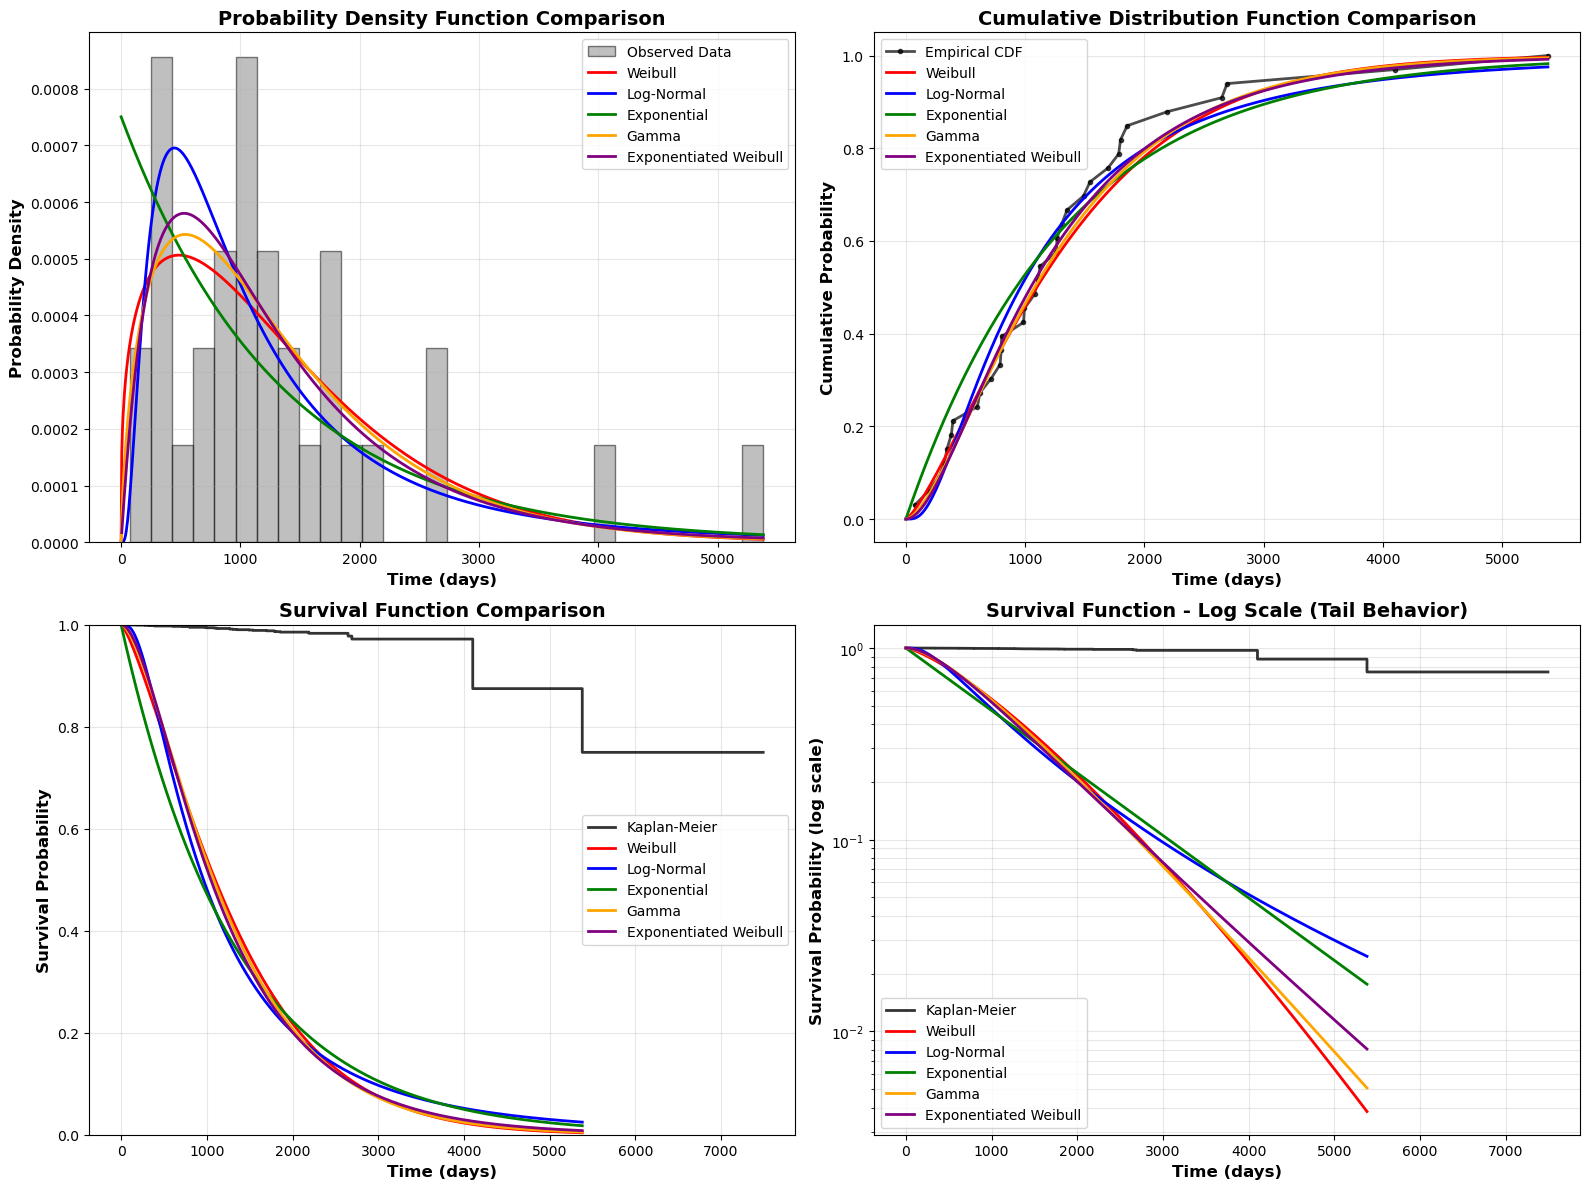

In [33]:
# Visual comparison: PDF (Probability Density Function)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Time points for plotting
time_points = np.linspace(0, uncensored_times.max(), 1000)

# 1. PDF Comparison
ax = axes[0, 0]
ax.hist(uncensored_times, bins=30, density=True, alpha=0.5, color='gray', 
        edgecolor='black', label='Observed Data')

colors = ['red', 'blue', 'green', 'orange', 'purple']
for (dist_name, dist_info), color in zip(distributions.items(), colors):
    dist = dist_info['dist']
    params = dist_info['params']
    pdf_values = dist.pdf(time_points, *params)
    ax.plot(time_points, pdf_values, linewidth=2, label=dist_name, color=color)

ax.set_xlabel('Time (days)', fontsize=12, fontweight='bold')
ax.set_ylabel('Probability Density', fontsize=12, fontweight='bold')
ax.set_title('Probability Density Function Comparison', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# 2. CDF Comparison
ax = axes[0, 1]
# Empirical CDF
sorted_times = np.sort(uncensored_times)
empirical_cdf = np.arange(1, len(sorted_times) + 1) / len(sorted_times)
ax.plot(sorted_times, empirical_cdf, 'o-', markersize=3, linewidth=2, 
        color='black', label='Empirical CDF', alpha=0.7)

for (dist_name, dist_info), color in zip(distributions.items(), colors):
    dist = dist_info['dist']
    params = dist_info['params']
    cdf_values = dist.cdf(time_points, *params)
    ax.plot(time_points, cdf_values, linewidth=2, label=dist_name, color=color)

ax.set_xlabel('Time (days)', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Probability', fontsize=12, fontweight='bold')
ax.set_title('Cumulative Distribution Function Comparison', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# 3. Survival Function Comparison
ax = axes[1, 0]
# Kaplan-Meier estimate
km_time, km_prob = kaplan_meier_estimator(event_occurred.astype(bool), event_times)
ax.step(km_time, km_prob, where='post', linewidth=2, color='black', 
        label='Kaplan-Meier', alpha=0.8)

for (dist_name, dist_info), color in zip(distributions.items(), colors):
    dist = dist_info['dist']
    params = dist_info['params']
    survival_values = 1 - dist.cdf(time_points, *params)
    ax.plot(time_points, survival_values, linewidth=2, label=dist_name, color=color)

ax.set_xlabel('Time (days)', fontsize=12, fontweight='bold')
ax.set_ylabel('Survival Probability', fontsize=12, fontweight='bold')
ax.set_title('Survival Function Comparison', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim([0, 1])

# 4. Log-scale comparison (useful for tail behavior)
ax = axes[1, 1]
ax.step(km_time, km_prob, where='post', linewidth=2, color='black', 
        label='Kaplan-Meier', alpha=0.8)

for (dist_name, dist_info), color in zip(distributions.items(), colors):
    dist = dist_info['dist']
    params = dist_info['params']
    survival_values = 1 - dist.cdf(time_points, *params)
    ax.plot(time_points, survival_values, linewidth=2, label=dist_name, color=color)

ax.set_xlabel('Time (days)', fontsize=12, fontweight='bold')
ax.set_ylabel('Survival Probability (log scale)', fontsize=12, fontweight='bold')
ax.set_title('Survival Function - Log Scale (Tail Behavior)', fontsize=14, fontweight='bold')
ax.set_yscale('log')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('distribution_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plots saved to 'distribution_comparison.png'")

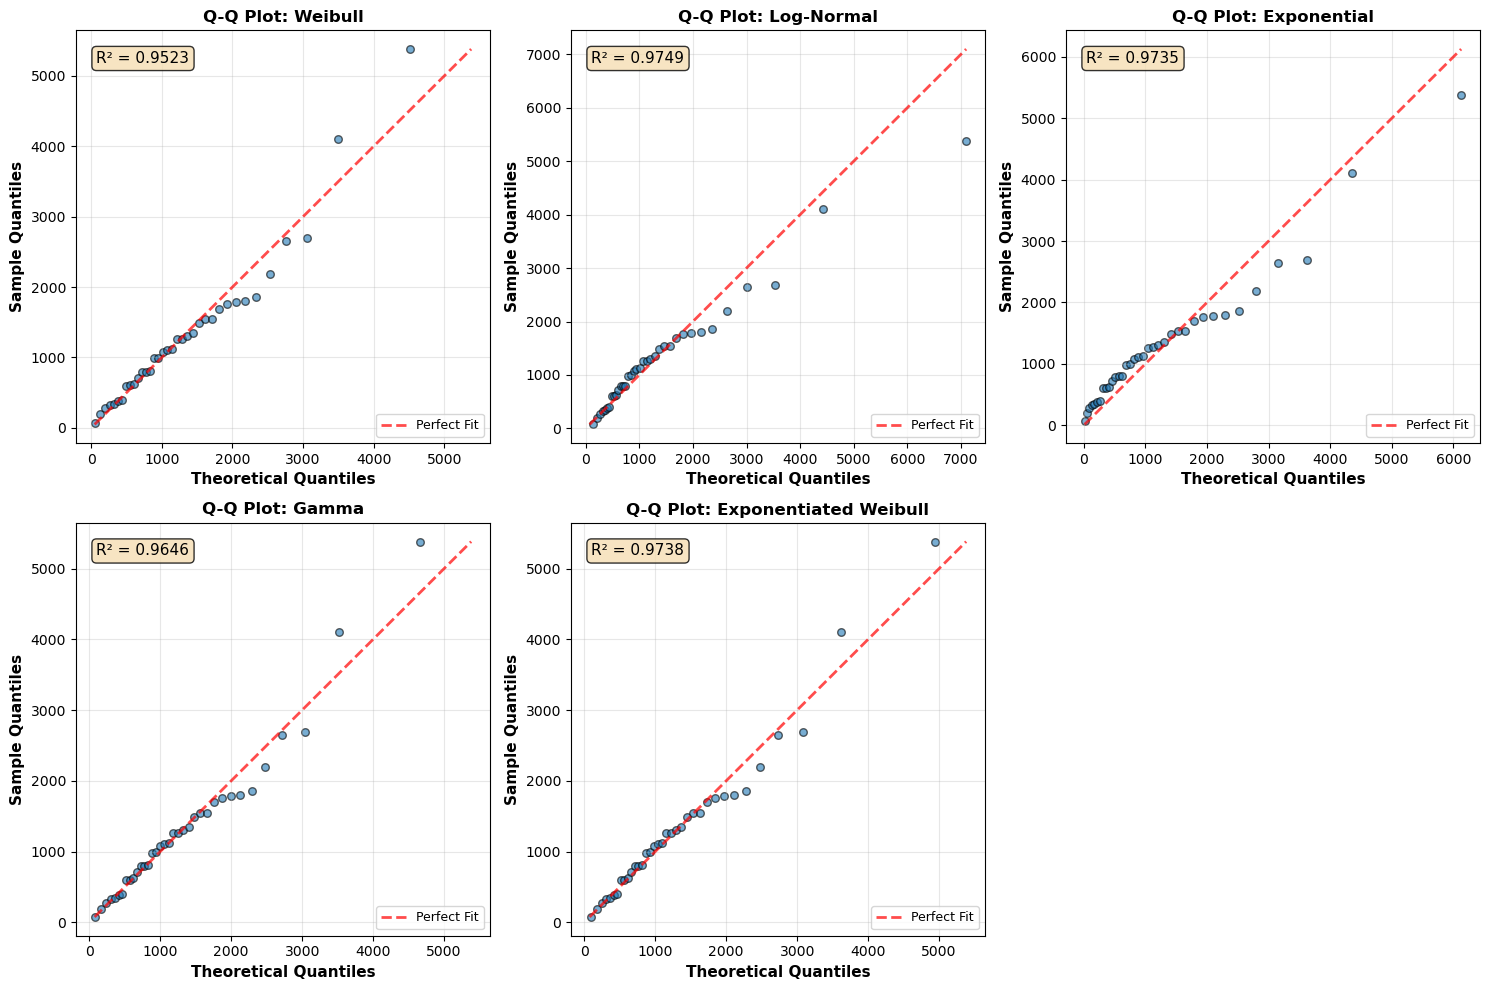

Q-Q plots saved to 'qq_plots.png'

Interpretation:
  - Points close to the red line indicate good fit
  - R² closer to 1.0 indicates better fit
  - Systematic deviations suggest poor fit


In [ ]:
# Q-Q Plots (Quantile-Quantile) - Best way to assess distribution fit
n_distributions = len(distributions)
n_cols = 3
n_rows = (n_distributions + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
if n_distributions == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for idx, (dist_name, dist_info) in enumerate(distributions.items()):
    ax = axes[idx]
    dist = dist_info['dist']
    params = dist_info['params']
    
    # Generate theoretical quantiles
    sorted_data = np.sort(uncensored_times)
    n = len(sorted_data)
    theoretical_quantiles = dist.ppf(np.linspace(0.01, 0.99, n), *params)
    
    # Q-Q plot
    ax.scatter(theoretical_quantiles, sorted_data, alpha=0.6, s=30, edgecolors='black')
    
    # Perfect fit line
    min_val = min(theoretical_quantiles.min(), sorted_data.min())
    max_val = max(theoretical_quantiles.max(), sorted_data.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, 
            label='Perfect Fit', alpha=0.7)
    
    # Calculate R² for the Q-Q plot
    mask = ~np.isnan(theoretical_quantiles) & ~np.isinf(theoretical_quantiles)
    if mask.sum() > 0:
        correlation = np.corrcoef(theoretical_quantiles[mask], sorted_data[mask])[0, 1]
        r_squared = correlation ** 2
        
        ax.text(0.05, 0.95, f'R² = {r_squared:.4f}', 
                transform=ax.transAxes, fontsize=11,
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    ax.set_xlabel('Theoretical Quantiles', fontsize=11, fontweight='bold')
    ax.set_ylabel('Sample Quantiles', fontsize=11, fontweight='bold')
    ax.set_title(f'Q-Q Plot: {dist_name}', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide extra subplots
for idx in range(n_distributions, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig('qq_plots.png', dpi=300, bbox_inches='tight')
plt.show()

print("Q-Q plots saved to 'qq_plots.png'")
print("\nInterpretation:")
print("  - Points close to the red line indicate good fit")
print("  - R² closer to 1.0 indicates better fit")
print("  - Systematic deviations suggest poor fit")

In [ ]:
# Summary and Recommendation
print("="*80)
print("DISTRIBUTION FIT SUMMARY")
print("="*80)

# Find best fitting distribution by different criteria
best_aic = fit_df.iloc[0]
best_ks = fit_df.loc[fit_df['KS p-value'].idxmax()] if fit_df['KS p-value'].max() > 0 else best_aic

print(f"\nBest fit by AIC: {best_aic['Distribution']}")
print(f"  AIC: {best_aic['AIC']:.2f}")
print(f"  KS p-value: {best_aic['KS p-value']:.4f}")

if best_ks['Distribution'] != best_aic['Distribution']:
    print(f"\nBest fit by KS test: {best_ks['Distribution']}")
    print(f"  AIC: {best_ks['AIC']:.2f}")
    print(f"  KS p-value: {best_ks['KS p-value']:.4f}")

print("\n" + "="*80)
print("RANKING BY DIFFERENT CRITERIA:")
print("="*80)

# Create ranking table
ranking_data = []
for dist_name in distributions.keys():
    dist_row = fit_df[fit_df['Distribution'] == dist_name].iloc[0]
    ranking_data.append({
        'Distribution': dist_name,
        'AIC Rank': (fit_df['AIC'] >= dist_row['AIC']).sum(),
        'BIC Rank': (fit_df['BIC'] >= dist_row['BIC']).sum(),
        'KS p-value': dist_row['KS p-value'],
        'AIC': dist_row['AIC'],
        'BIC': dist_row['BIC']
    })

ranking_df = pd.DataFrame(ranking_data).sort_values('AIC Rank')
print(ranking_df.to_string(index=False))

print("\n" + "="*80)
print("RECOMMENDATIONS:")
print("="*80)
print(f"""
1. PRIMARY RECOMMENDATION: {best_aic['Distribution']}
   - Lowest AIC/BIC values indicate best statistical fit
   - Use this for parametric survival modeling

2. Visual inspection is also important:
   - Check Q-Q plots: Points should align with red line
   - Check survival curves: Should match Kaplan-Meier estimate
   
3. Domain knowledge considerations:
   - Weibull: Most common for survival data, flexible hazard
   - Log-Normal: Appropriate for multiplicative effects
   - Exponential: Constant hazard rate (memoryless property)
   - Gamma: Allows for increasing hazard early on

4. If KS p-value < 0.05 for all distributions:
   - Consider non-parametric methods (Kaplan-Meier, Cox model)
   - Or use mixture distributions
""")

DISTRIBUTION FIT SUMMARY

Best fit by AIC: Gamma
  AIC: 589.93
  KS p-value: 0.8426

Best fit by KS test: Exponentiated Weibull
  AIC: 591.70
  KS p-value: 0.8955

RANKING BY DIFFERENT CRITERIA:
         Distribution  AIC Rank  BIC Rank  KS p-value        AIC        BIC
          Exponential         1         3    0.232851 593.891264 597.058302
           Log-Normal         2         2    0.683271 592.354084 597.104640
Exponentiated Weibull         3         1    0.895456 591.699081 598.033157
              Weibull         4         4    0.723072 590.874779 595.625336
                Gamma         5         5    0.842612 589.930366 594.680923

RECOMMENDATIONS:

1. PRIMARY RECOMMENDATION: Gamma
   - Lowest AIC/BIC values indicate best statistical fit
   - Use this for parametric survival modeling

2. Visual inspection is also important:
   - Check Q-Q plots: Points should align with red line
   - Check survival curves: Should match Kaplan-Meier estimate

3. Domain knowledge consideratio

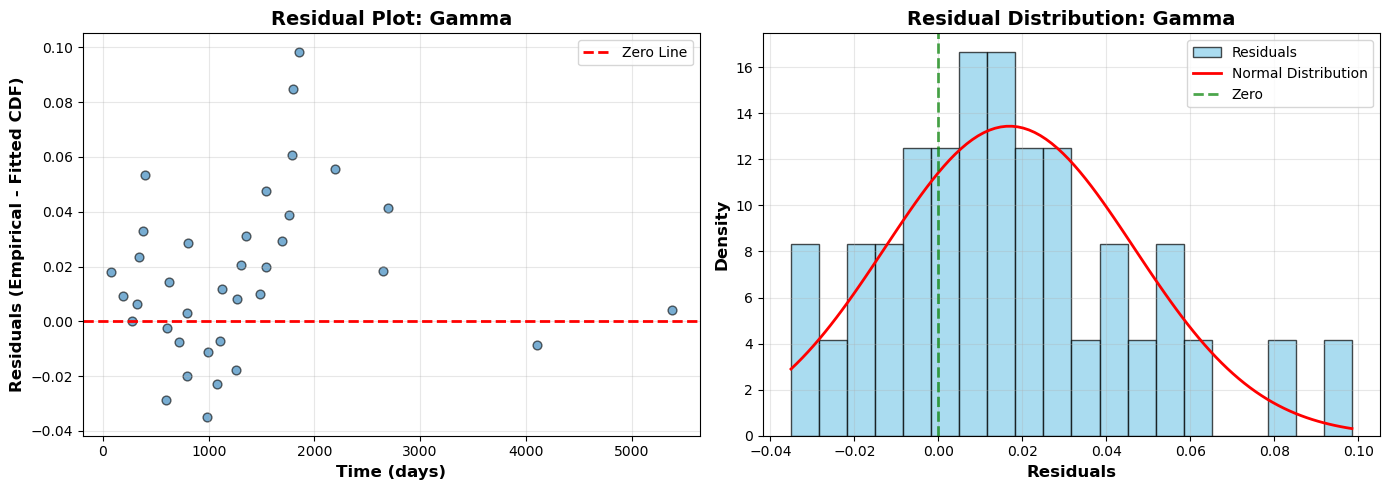


Residual Analysis for Gamma:
  Mean residual: 0.016921 (should be close to 0)
  Std residual: 0.029686
  Max absolute residual: 0.098470

Interpretation:
  - Residuals should be randomly scattered around zero
  - No systematic patterns indicate good fit
  - Mean close to 0 indicates unbiased fit


In [ ]:
# Optional: Residual Analysis for the best fitting distribution
best_dist_name = best_aic['Distribution']
best_dist_info = distributions[best_dist_name]
best_dist = best_dist_info['dist']
best_params = best_dist_info['params']

# Calculate residuals (observed - expected CDF)
sorted_times = np.sort(uncensored_times)
empirical_cdf = np.arange(1, len(sorted_times) + 1) / len(sorted_times)
fitted_cdf = best_dist.cdf(sorted_times, *best_params)
residuals = empirical_cdf - fitted_cdf

# Plot residuals
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residual plot
ax = axes[0]
ax.scatter(sorted_times, residuals, alpha=0.6, s=40, edgecolors='black')
ax.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Line')
ax.set_xlabel('Time (days)', fontsize=12, fontweight='bold')
ax.set_ylabel('Residuals (Empirical - Fitted CDF)', fontsize=12, fontweight='bold')
ax.set_title(f'Residual Plot: {best_dist_name}', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Histogram of residuals
ax = axes[1]
ax.hist(residuals, bins=20, density=True, alpha=0.7, color='skyblue', 
        edgecolor='black', label='Residuals')
# Overlay normal distribution
mean_resid = residuals.mean()
std_resid = residuals.std()
x_norm = np.linspace(residuals.min(), residuals.max(), 100)
ax.plot(x_norm, stats.norm.pdf(x_norm, mean_resid, std_resid), 
        'r-', linewidth=2, label='Normal Distribution')
ax.axvline(x=0, color='green', linestyle='--', linewidth=2, alpha=0.7, label='Zero')
ax.set_xlabel('Residuals', fontsize=12, fontweight='bold')
ax.set_ylabel('Density', fontsize=12, fontweight='bold')
ax.set_title(f'Residual Distribution: {best_dist_name}', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'residual_analysis_{best_dist_name.lower().replace(" ", "_")}.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print(f"\nResidual Analysis for {best_dist_name}:")
print(f"  Mean residual: {mean_resid:.6f} (should be close to 0)")
print(f"  Std residual: {std_resid:.6f}")
print(f"  Max absolute residual: {np.abs(residuals).max():.6f}")
print("\nInterpretation:")
print("  - Residuals should be randomly scattered around zero")
print("  - No systematic patterns indicate good fit")
print("  - Mean close to 0 indicates unbiased fit")